# P5: PyTorch and Policy Gradient Methods

> **Note: Machine learning for this assignment runs on your laptop's CPU and takes a while: 2–5 minutes per CartPole run (P5.2), 3–5 minutes for each of the three Pendulum training cells (P5.3), and 1–2 minutes per PPO run (P5.4). All told, it could take ~2 hours to run from scratch.**

In this assignment, you will be implementing your own approximate reinforcement learning methods. You will be using a few new packages: `torch` (the PyTorch package, focused on training deep learning algorithms), `gymnasium`, which implements a few classical control environments that we will be using to evaluate our RL algorithms, and `stable_baselines3` (in P5.4). Run the following to make sure they are installed:

In [1]:
# Check that the packages for this assignment are installed
import importlib.util

missing = [
    name
    for name in ["torch", "gymnasium", "pygame", "stable_baselines3", "pandas"]
    if importlib.util.find_spec(name) is None
]
if missing:
    raise ImportError(
        f"Missing: {', '.join(missing)}. Update your pyproject.toml to the latest course version and "
        "restart with `uv run launch-assignment-notebooks`"
    )
print("All packages are installed.")

All packages are installed.


In [2]:
## Starter Code
from IPython import display
import gymnasium as gym
import torch
from torch import nn
import numpy as np
import random
import matplotlib.pyplot as plt


def smooth_data(data, window_width=50):
    summed_data = np.cumsum(data)
    sm_data = (summed_data[window_width:] - summed_data[:-window_width]) / window_width
    return np.concatenate([np.zeros(window_width), sm_data])


def rollout(env, policy, epsilon, do_visualize=False):
    state, _ = env.reset()
    done = False
    data = []
    if do_visualize:
        img = plt.imshow(env.render())
    while not done:
        if do_visualize:
            img.set_data(env.render())
            display.display(plt.gcf())
            display.clear_output(wait=True)
        action = policy.sample_action(state, epsilon)
        try:
            new_state, reward, terminated, truncated, _ = env.step(action)
        except:
            new_state, reward, terminated, truncated, _ = env.step([action])
        done = terminated or truncated
        data.append((state, action, reward, new_state, done))
        state = new_state

    return data

## P5.1 Curve Fitting

As a starting point, we will go through some simple code to test your understanding of Gradient Descent to solve a curve fitting problem.

PyTorch, like most popular deep learning tools, supports "autodiff", a tool for automatically computing derivatives of many common functions used in neural networks, making it easy to perform gradient descent. PyTorch has built-in optimization tools as well, which we used to implement curve fitting in the example we did in class, reproduced here as a starting point for the remainder of this question.

**TASK** Run the "Curve Fitting Starter Code" below and confirm that your FitFunction approximates the data.

Step:      0  |    y = 0.114 + 0.219*x + -0.031*x^2 + -0.803*x^3  |  Loss: 23.87244415283203
Step:    250  |    y = 1.139 + 1.115*x + 0.793*x^2 + 0.041*x^3  |  Loss: 10.514031410217285
Step:    500  |    y = 1.788 + 1.169*x + 1.338*x^2 + 0.126*x^3  |  Loss: 63.08962631225586
Step:    750  |    y = 2.130 + 1.055*x + 1.686*x^2 + 0.126*x^3  |  Loss: 1.6698983907699585
Step:   1000  |    y = 2.187 + 0.906*x + 1.817*x^2 + 0.124*x^3  |  Loss: 0.000661918893456459
Step:   1250  |    y = 2.145 + 0.764*x + 1.873*x^2 + 0.148*x^3  |  Loss: 0.010316642001271248
Step:   1500  |    y = 2.058 + 0.582*x + 1.900*x^2 + 0.160*x^3  |  Loss: 3.2367799282073975
Step:   1750  |    y = 1.893 + 0.385*x + 1.904*x^2 + 0.163*x^3  |  Loss: 2.2895100116729736
Step:   2000  |    y = 1.766 + 0.183*x + 1.926*x^2 + 0.173*x^3  |  Loss: 1.9773820638656616
Step:   2250  |    y = 1.612 + -0.035*x + 1.935*x^2 + 0.179*x^3  |  Loss: 0.5279973745346069
Step:   2500  |    y = 1.469 + -0.256*x + 1.930*x^2 + 0.201*x^3  |  Loss: 2

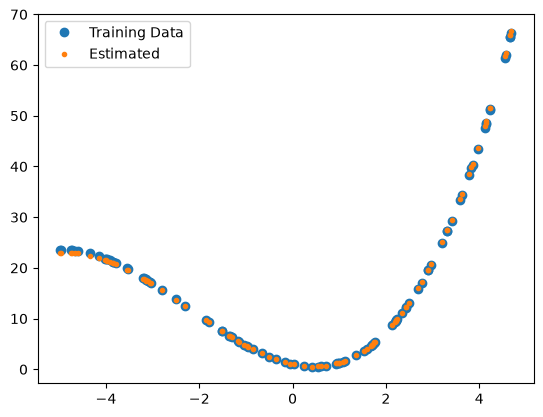

In [3]:
# Curve Fitting Starter Code [From the in-class example]

import numpy as np
import matplotlib.pyplot as plt
import torch


class FitFunction(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.a = torch.nn.Parameter(torch.randn(()))
        self.b = torch.nn.Parameter(torch.randn(()))
        self.c = torch.nn.Parameter(torch.randn(()))
        self.d = torch.nn.Parameter(torch.randn(()))

    def forward(self, x):
        return self.a + self.b * x + self.c * x**2 + self.d * x**3

    def string(self):
        return f"  y = {self.a.item():.3f} + {self.b.item():.3f}*x + {self.c.item():.3f}*x^2 + {self.d.item():.3f}*x^3"


def compute_loss(y, y_pred):
    return 0.5 * (y_pred - y) ** 2


# Generate some data from the curve we're trying to fit
xs = np.random.rand(100) * 10 - 5
ys = 1 - 2 * xs + 2 * (xs**2) + 0.3 * (xs**3)
plt.plot(xs, ys, "o")

# Instantiate the function with random guesses of the coefficients
model = FitFunction()

# Optimization loop
num_optim_steps = 20000
learning_rate = 1e-2
optim = torch.optim.Adam(model.parameters(), lr=learning_rate)

for t in range(num_optim_steps):
    # Get a random data point
    ind = np.random.randint(0, len(xs))
    y = ys[ind]

    # Make a prediction and compute the loss
    y_pred = model(xs[ind])
    loss = compute_loss(y, y_pred)

    # Debug print outputs
    if t % 250 == 0:
        print(f"Step: {t:6d}  |  " + model.string() + f"  |  Loss: {loss.item()}")

    # .backward() computes the gradient that the optimizer uses to train
    loss.backward()
    optim.step()
    optim.zero_grad()

# Compute the estimated values for all the data points (on training data...)
y_estimated = model(torch.tensor(xs)).detach().numpy()
plt.plot(xs, y_estimated, ".")
plt.gca().legend(["Training Data", "Estimated"])
None


### P5.1.1 Using an alternate update rule

We use the common "squared loss", equivalent to the "Mean Squared Error" used in linear algebra curve fitting problems. The loss is defined as follows:

$$\text{Loss} = \frac{1}{2}(y_\text{pred} - y) ^ 2 $$

In class, we discussed that the squared loss function gives rise to the following update rule (via gradient descent):

$$ \theta_\text{new} = \theta_\text{old} - \eta \nabla_\theta \text{Loss} \text{ [Update Rule \#1]}$$

$$ \theta_\text{new} = \theta_\text{old} - \eta (y_\text{pred} - y) \nabla_\theta y_\text{pred} \text{ [Update Rule \#2]}$$

where $\eta$ is the learning rate and $\nabla_\theta$ is the gradient with respect to the parameters $\theta$. Note that both rules are equivalent to one another. This can be easily derived from the chain rule, since $\nabla_\theta \frac{1}{2}(f(\theta) - a)^2 = (f(\theta) - a) \nabla_\theta f(\theta)$. You will show this equivalence in PyTorch by writing a new `compute_loss` function that matches [Update Rule #2].

In the RL scenarios in the questions below, you will want to be able to optimize scenarios that resemble [Update Rule #2]. As practice for this, your first task is to define a new `compute_loss_v2` function that looks like [Update Rule #2]. Note that using `loss = (y_pred - y) * y_pred` will *not* succeed, since both terms are differentiable with respect to the parameters $\theta$. To avoid this issue, you'll need to "detach" the terms for which you don't want to compute a gradient. There are two ways to do this in PyTorch:

```python

# _V1_
with torch.no_grad():
    # This is treated as a constant by PyTorch
    y_pred_constant = model(x)

# _V2_
# This is also treated as a constant by PyTorch
y_pred_constant = model(x).detach()
```

**TASK+CODE** Implement `compute_loss_v2`, which should rely on one of the two "detach" functions above. Note that the result you obtain in using this function should closely resemble the first version and the fit function should closely fit the data. You do not need to include the resulting plot in your writeup (but you should include your code!)

In [4]:
# Starter Code: compute loss
def compute_loss_v2(y, y_pred):
    y_pred_cont = y_pred.detach()
    return y_pred * (y_pred_cont - y)

Step:      0  |    y = 0.099 + 0.063*x + 2.746*x^2 + 0.181*x^3  |  Loss: 549.5466918945312
Step:    250  |    y = -0.566 + -0.166*x + 2.068*x^2 + 0.215*x^3  |  Loss: -21.531017303466797
Step:    500  |    y = -0.224 + -0.530*x + 2.032*x^2 + 0.219*x^3  |  Loss: 13.891199111938477
Step:    750  |    y = 0.076 + -0.914*x + 2.014*x^2 + 0.235*x^3  |  Loss: -33.66338348388672
Step:   1000  |    y = 0.346 + -1.209*x + 2.019*x^2 + 0.264*x^3  |  Loss: 3.4910826683044434
Step:   1250  |    y = 0.523 + -1.474*x + 2.014*x^2 + 0.274*x^3  |  Loss: 10.6228666305542
Step:   1500  |    y = 0.657 + -1.668*x + 2.021*x^2 + 0.288*x^3  |  Loss: -12.56088924407959
Step:   1750  |    y = 0.799 + -1.815*x + 2.007*x^2 + 0.291*x^3  |  Loss: 0.522860050201416
Step:   2000  |    y = 0.877 + -1.893*x + 2.013*x^2 + 0.292*x^3  |  Loss: 0.9263964891433716
Step:   2250  |    y = 0.932 + -1.945*x + 2.006*x^2 + 0.297*x^3  |  Loss: 0.6996375322341919
Step:   2500  |    y = 0.966 + -1.977*x + 2.003*x^2 + 0.298*x^3  |  Loss

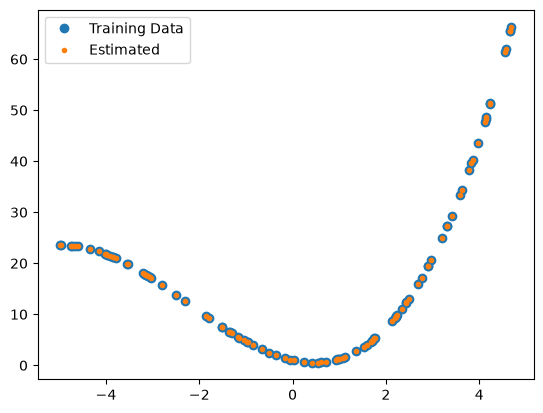

In [5]:
# Use the new loss function to train.

model = FitFunction()

# Optimization loop
num_optim_steps = 10000
learning_rate = 1e-2
optim = torch.optim.Adam(model.parameters(), lr=learning_rate)

for t in range(num_optim_steps):
    # Get a random data point
    ind = np.random.randint(0, len(xs))
    y = ys[ind]

    # Make a prediction and compute the loss
    y_pred = model(xs[ind])
    loss = compute_loss_v2(y, y_pred)

    # Debug print outputs
    if t % 250 == 0:
        print(f"Step: {t:6d}  |  " + model.string() + f"  |  Loss: {loss.item()}")

    # .backward() computes the gradient that the optimizer uses to train
    loss.backward()
    optim.step()
    optim.zero_grad()

# Compute the estimated values for all the data points (on training data...)
y_estimated = model(torch.tensor(xs)).detach().numpy()
plt.plot(xs, ys, "o")
plt.plot(xs, y_estimated, ".")
plt.gca().legend(["Training Data", "Estimated"])
None

### P5.1.2 Fitting to 2D data

I have provided you with some sample `2D` data that you should fit to using Gradient Descent.

**TASK** Complete `FitFunction2D` and write a script (using the 1D case as a starting point) that estimates the `zs` from the `xs` and `ys`.

**CODE** Include the resulting class definition and script in your writeup. If run, your code should nearly perfectly fit the data I have provided.

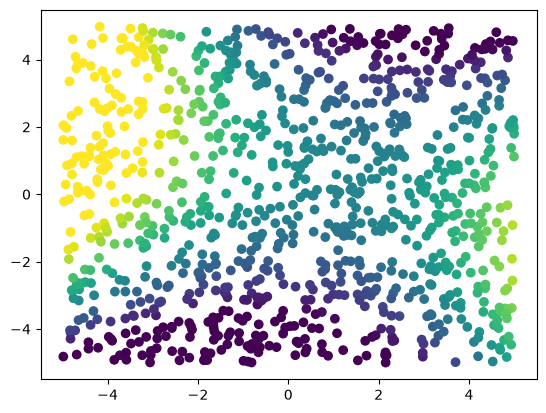

In [6]:
# Starter Code: 2D Data

# Generate some data from the curve we're trying to fit
xs = np.random.rand(1000) * 10 - 5
ys = np.random.rand(1000) * 10 - 5
zs = -1 - 2 * xs + 2 * ys + xs**2 - ys**2 - xs * ys

plt.figure()
plt.scatter(xs, ys, c=zs, vmin=-20, vmax=20)


class FitFunction2D(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.a = torch.nn.Parameter(torch.randn(()))
        self.b = torch.nn.Parameter(torch.randn(()))
        self.c = torch.nn.Parameter(torch.randn(()))
        self.d = torch.nn.Parameter(torch.randn(()))
        self.e = torch.nn.Parameter(torch.randn(()))
        self.f = torch.nn.Parameter(torch.randn(()))

    def forward(self, x, y):
        return self.a + self.b * x + self.c * y + self.d * x**2 + self.e * y**2 + self.f * x * y

    def string(self):
        return "Replace this if you wish! It's only for debugging/sanity checking"


None

Step:      0  |  Replace this if you wish! It's only for debugging/sanity checking  |  Loss: 0.3344816267490387


Step:   1000  |  Replace this if you wish! It's only for debugging/sanity checking  |  Loss: 0.10265854001045227
Step:   2000  |  Replace this if you wish! It's only for debugging/sanity checking  |  Loss: 0.00015832405188120902
Step:   3000  |  Replace this if you wish! It's only for debugging/sanity checking  |  Loss: 0.00010106690024258569
Step:   4000  |  Replace this if you wish! It's only for debugging/sanity checking  |  Loss: 3.364402800798416e-08
Step:   5000  |  Replace this if you wish! It's only for debugging/sanity checking  |  Loss: 3.439026841078885e-12
Step:   6000  |  Replace this if you wish! It's only for debugging/sanity checking  |  Loss: 1.8189894035458565e-12
Step:   7000  |  Replace this if you wish! It's only for debugging/sanity checking  |  Loss: 0.0005990179488435388
Step:   8000  |  Replace this if you wish! It's only for debugging/sanity checking  |  Loss: 0.00018533470574766397
Step:   9000  |  Replace this if you wish! It's only for debugging/sanity chec

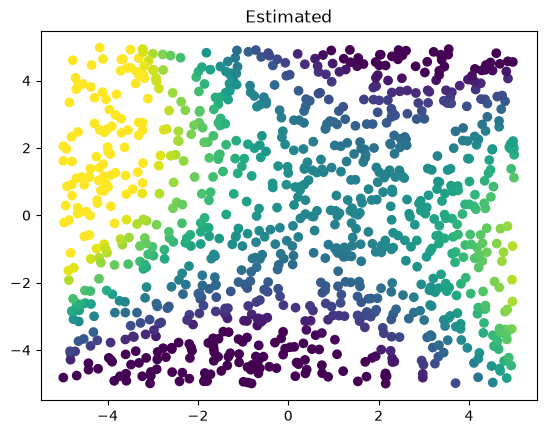

In [7]:
model2d = FitFunction2D()

num_optim_steps = 20000
learning_rate = 1e-2
optim = torch.optim.Adam(model2d.parameters(), lr=learning_rate)

for t in range(num_optim_steps):
    ind = np.random.randint(0, len(xs))
    x, y, z = xs[ind], ys[ind], zs[ind]

    z_pred = model2d(x, y)
    loss = compute_loss(z, z_pred)   # the original squared loss from P5.1

    if t % 1000 == 0:
        print(f"Step: {t:6d}  |  " + model2d.string() + f"  |  Loss: {loss.item()}")

    loss.backward()
    optim.step()
    optim.zero_grad()

# Plot the fit next to the data
z_estimated = model2d(torch.tensor(xs), torch.tensor(ys)).detach().numpy()
plt.figure()
plt.scatter(xs, ys, c=z_estimated, vmin=-20, vmax=20)
plt.title("Estimated")
None


## P5.2 Policy Learning in the CartPole Environment

In class we discussed the CartPole Environment, described and defined in detail here: https://gymnasium.farama.org/environments/classic_control/cart_pole/ . You will be using this environment to develop the three policy gradient algorithms we defined in lecture.

*Note: we use `CartPole-v1`, whose episodes end after 500 steps, so the maximum possible return is 500.*

### P5.2.1 Defining the Policy

Below, I have provided you with a partial implementation of the `PolicyApprox` function, which will take in the state of the environment and return a probability for each action. I have defined a simple neural network that ends with a "softmax" operation, ensuring that the output is normalized and so is a valid probability distribution.

**TASK+CODE** Complete the `sample_action` and `get_action_log_prob` functions in the partial implementation of the `PolicyApprox` class. Note that the `sample_action` function takes in a parameter `epsilon`, so that your policy is an epsilon-greedy "soft policy": epsilon percent of the time, the policy should pick a random action with uniform probability. The rest of the time, you should pick an action with a probability specified by the likelihoods output by the neural network. You may find `np.random.choice` a helpful function for this in your implementation. Include the completed functions in your writeup.

**TASK** Once you've completed the approximate policy class, run the "Results and Plotting" code below it a few times and observe the results.

**QUESTION** (2-4 sentences) Roughly how many steps does the typical trial manage before the pole falls to the side? Describe what behavior you should expect to keep the pendulum up.

In [8]:
## Policy Approximation Starter Code


class PolicyApprox(torch.nn.Module):
    def __init__(self, n_states, n_actions):
        super().__init__()
        # A single hidden layer neural network
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(n_states, 32),
            nn.Tanh(),
            nn.Linear(32, n_actions),
            nn.Softmax(dim=-1),
        )

    def forward(self, state):
        return self.linear_relu_stack(torch.tensor(state, dtype=torch.float))

    def sample_action(self, state, epsilon=0.0):
        # Move data out of PyTorch and into numpy
        policy_outputs = self(state).detach().numpy()
        n_actions = len(policy_outputs)

        # Epsilon-greedy soft policy: with probability epsilon, pick uniformly at random
        if np.random.rand() < epsilon:
            action = np.random.choice(n_actions)
        else:
            # Otherwise sample from the network's action probabilities
            action = np.random.choice(n_actions, p=policy_outputs / policy_outputs.sum())


        return action

    def get_action_log_prob(self, state, action):
        """Return the log of the probability associated with a particular action for a particular state."""
        probs = self(state)
        return torch.log(probs[action])

Num steps before failure: 11


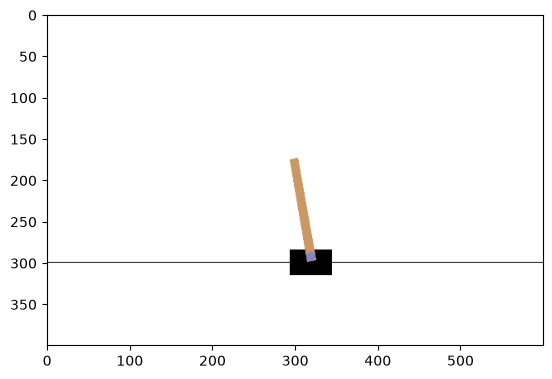

In [9]:
# Results and Plotting

env = gym.make("CartPole-v1", render_mode="rgb_array")

policy = PolicyApprox(
    n_states=len(env.observation_space.low), n_actions=env.action_space.n
)

rollout_data = rollout(env, policy, epsilon=0, do_visualize=True)

print(f"Num steps before failure: {len(rollout_data)}")

### P5.2.2 Implementing REINFORCE

In lecture, we discussed the REINFORCE algorithm, as presented in Chapter 13.3 in Sutton & Barto. Below, I have presented you with a partial implementation of REINFORCE.

**TASK+CODE** Complete the REINFORCE algorithm below using the lecture slides or Sutton & Barto as a reference. Include your definition of the loss function in your writeup. Note that to implement the algorithm, you may need to use what you learned in P5.1.1, so make sure you've done that question first.

**PLOTS** Run the Results & Plotting code using your newly-implemented REINFORCE implementation. Include the plot in your writeup.

**QUESTION** (2–4 sentences) Run the Results & Plotting code a few more times (3–5 times will be sufficient) and comment on the similarities and differences between the results and behavior of the system (e.g., how does the random initial configuration impact the performance of the system?)

**TASK+QUESTION+PLOT** (3–5 sentences) Increase the learning rate to `learning_rate=0.01` and run the results and plotting code a few more times. Include one of the plots in your writeup. How is the performance similar or different to the base configuration?

**TASK+QUESTION+PLOT** (3–5 sentences) Decrease the learning rate to `learning_rate=1e-4` and run the results and plotting code a few more times. Include one of the plots in your writeup. How is the performance similar or different to the base configuration?

In [35]:
# REINFORCE Starter Code


def reinforce(
    env, policy, num_episodes, learning_rate=1e-4, gamma=0.95, epsilon0=0.1
):
    optim = torch.optim.Adam(policy.parameters(), lr=learning_rate)
    all_rewards = []
    for ind in range(num_episodes):
        # Rollout
        rollout_data = rollout(env, policy, epsilon=epsilon0 / np.log10(ind + 2))

        G = 0
        loss = 0
        total_reward = 0
        for state, action, reward, new_state, done in reversed(rollout_data):
            total_reward += reward
            G = gamma * G + reward
            loss = loss - G * policy.get_action_log_prob(state,action)

        loss.backward()
        optim.step()
        optim.zero_grad()

        all_rewards.append(total_reward)
        if ind % 100 == 0:
            print(ind, total_reward, loss)

    return all_rewards

0 11.0 tensor(44.7359, grad_fn=<SubBackward0>)
100 17.0 tensor(77.7996, grad_fn=<SubBackward0>)
200 15.0 tensor(58.3503, grad_fn=<SubBackward0>)
300 33.0 tensor(252.9178, grad_fn=<SubBackward0>)
400 12.0 tensor(48.3833, grad_fn=<SubBackward0>)
500 15.0 tensor(63.3465, grad_fn=<SubBackward0>)
600 24.0 tensor(143.7490, grad_fn=<SubBackward0>)
700 16.0 tensor(72.6936, grad_fn=<SubBackward0>)
800 32.0 tensor(230.9240, grad_fn=<SubBackward0>)
900 11.0 tensor(40.8200, grad_fn=<SubBackward0>)
1000 14.0 tensor(57.7606, grad_fn=<SubBackward0>)
1100 59.0 tensor(559.4488, grad_fn=<SubBackward0>)
1200 13.0 tensor(52.9919, grad_fn=<SubBackward0>)
1300 14.0 tensor(58.5405, grad_fn=<SubBackward0>)
1400 50.0 tensor(437.4396, grad_fn=<SubBackward0>)
1500 13.0 tensor(56.0425, grad_fn=<SubBackward0>)
1600 51.0 tensor(447.8098, grad_fn=<SubBackward0>)
1700 12.0 tensor(49.2273, grad_fn=<SubBackward0>)
1800 10.0 tensor(36.5520, grad_fn=<SubBackward0>)
1900 42.0 tensor(332.8971, grad_fn=<SubBackward0>)
2000 

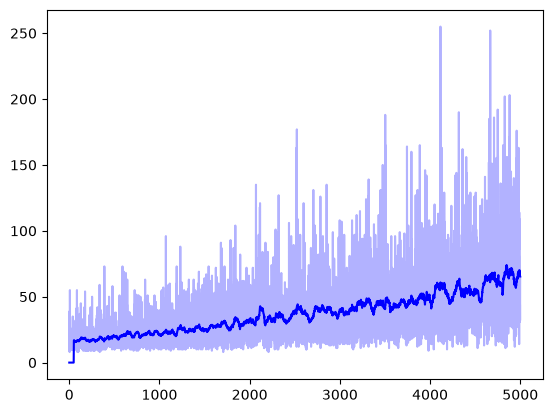

In [36]:
# Results and Plotting

env = gym.make("CartPole-v1", render_mode="rgb_array")

policy = PolicyApprox(
    n_states=len(env.observation_space.low), n_actions=env.action_space.n
)

REINFORCE_rewards = reinforce(env, policy, num_episodes=5000)
plt.figure()
plt.clf()
plt.plot(smooth_data(REINFORCE_rewards, window_width=50), "b")
plt.plot(REINFORCE_rewards, "b", alpha=0.3)
plt.show()

Num steps before failure: 77


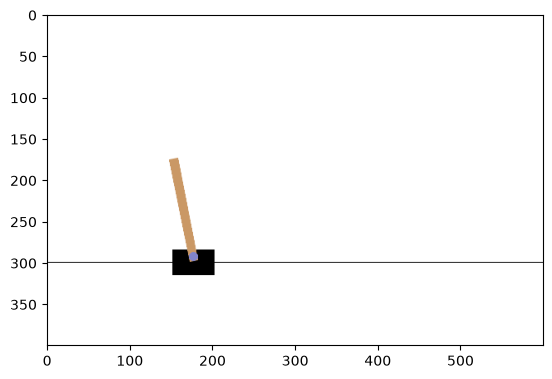

In [37]:
# Optional: See how your policy performed
rollout_data = rollout(env, policy, epsilon=0, do_visualize=True)
print(f"Num steps before failure: {len(rollout_data)}")

### P5.2.3 Implementing REINFORCE with Baseline

In lecture, we discussed the REINFORCE with Baseline algorithm, as presented in Chapter 13.4 in Sutton & Barto. This approach requires training both the policy function and also an estimator for the state value function V. I have provided you with a class `VApprox` that you should use for this purpose.

**TASK+CODE** Complete the REINFORCE with baseline algorithm below using the lecture slides or Sutton & Barto as a reference (and, of course, your code from P5.2.2). Include your implementation of REINFORCE with baseline in your writeup.

**PLOTS** Run the Results & Plotting code using your newly-implemented REINFORCE with Baseline implementation. Include the plot in your writeup.

**QUESTION** (2–4 sentences) Run the Results & Plotting code a few more times (3–5 times will be sufficient) and comment on the similarities and differences between the results and behavior of the system (e.g., how does the random initial configuration impact the performance of the system?)

**QUESTION** (3–5 sentences) How does the performance of REINFORCE with Baseline compare to the plain REINFORCE algorithm from P5.2.2? Comment on their relative performance. Which would you prefer to use and why?

[Feel free to use the rollout + visualization code to visualize your result]

In [13]:
# Starter Code: REINFORCE with Baseline


class VApprox(torch.nn.Module):
    def __init__(self, n_states):
        super().__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(n_states, 32),
            nn.Tanh(),
            nn.Linear(32, 1),
        )

    def forward(self, state):
        return 100 * self.linear_relu_stack(torch.tensor(state, dtype=torch.float))


def reinforce_with_baseline(
    env, policy, V, num_episodes, learning_rate=0.0005, gamma=0.95, epsilon0=0.1
):
    optim = torch.optim.Adam(policy.parameters(), lr=learning_rate)  # optim
    v_optim = torch.optim.Adam(V.parameters(), lr=learning_rate)  # optim
    all_rewards = []
    for ind in range(num_episodes):
        rollout_data = rollout(env, policy, epsilon=epsilon0 / np.log10(ind + 2))

        G = 0
        policy_loss = 0
        v_loss = 0
        total_reward = 0
        for state, action, reward, new_state, done in reversed(rollout_data):
            total_reward += reward
            G = gamma * G + reward

            v_pred = V(state).squeeze()

            # Advantage: G - V(s). Detached so the policy loss does not
            # push gradients into V (same trick as P5.1.1).
            delta = G - v_pred.detach()

            # Policy: ascend delta * grad log pi(a|s)  (S&B 13.4)
            policy_loss = policy_loss - delta * policy.get_action_log_prob(state, action)

            # Value: squared loss toward the return G, which gives the update
            # (G - V) * grad V
            v_loss = v_loss + 0.5 * (G - v_pred) ** 2

        policy_loss.backward()
        v_loss.backward()
        optim.step()
        v_optim.step()
        optim.zero_grad()
        v_optim.zero_grad()

        all_rewards.append(total_reward)
        if ind % 100 == 0:
            print(ind, total_reward, policy_loss.item())

    return all_rewards

0 17.0 -153.11398315429688
100 26.0 14.951967239379883
200 17.0 -21.542539596557617
300 15.0 -61.1057014465332
400 28.0 -60.02266311645508
500 42.0 -36.6146240234375
600 43.0 -90.01205444335938
700 130.0 -27.906734466552734
800 250.0 -66.31034088134766
900 459.0 -314.8332214355469
1000 416.0 -175.22488403320312
1100 363.0 205.77903747558594
1200 167.0 3.432971239089966
1300 137.0 -206.1123809814453
1400 203.0 -9.586928367614746
1500 164.0 -8.304142951965332
1600 134.0 -67.6231689453125
1700 294.0 -163.60589599609375
1800 197.0 6.695195198059082
1900 500.0 40.391414642333984
2000 183.0 -8.603083610534668
2100 157.0 -69.53809356689453
2200 493.0 278.9683532714844
2300 435.0 117.71459197998047
2400 500.0 42.15204620361328
2500 377.0 26.718000411987305
2600 500.0 -110.95970153808594
2700 500.0 170.19688415527344
2800 487.0 185.044921875
2900 500.0 -118.05501556396484
3000 500.0 -124.20498657226562
3100 500.0 -0.6676565408706665
3200 500.0 91.50457763671875
3300 389.0 120.63231658935547
340

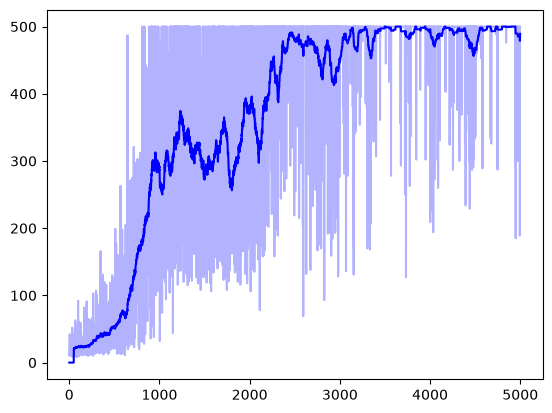

In [14]:
# Results and Plotting

env = gym.make("CartPole-v1", render_mode="rgb_array")

policy = PolicyApprox(
    n_states=len(env.observation_space.low), n_actions=env.action_space.n
)
V = VApprox(n_states=len(env.observation_space.low))

REINFORCE_with_baseline_rewards = reinforce_with_baseline(
    env, policy, V, num_episodes=5000
)

plt.figure()
plt.clf()
plt.plot(smooth_data(REINFORCE_with_baseline_rewards, window_width=50), "b")
plt.plot(REINFORCE_with_baseline_rewards, "b", alpha=0.3)
plt.show()

### P5.2.4 Implementing Actor-Critic

Finally, you'll implement the Actor-Critic algorithm, a TD-version of the REINFORCE with Baseline training strategy. Using what you've implemented so far, you will complete the `actor_critic` function below.

**TASK+CODE** Complete the Actor-Critic algorithm below using the lecture slides or Sutton & Barto as a reference (and, of course, your code from P5.2.3). Include your implementation in your writeup.

**PLOTS** Run the Results & Plotting code using your newly-implemented Actor-Critic implementation. Include the plot in your writeup.

**QUESTION** (2–4 sentences) Run the Results & Plotting code a few more times (3–5 times will be sufficient) and comment on the similarities and differences between the results and behavior of the system (e.g., how does the random initial configuration impact the performance of the system?)

[Feel free to use the rollout + visualization code from above to visualize your result]

In [15]:
# Actor Critic Starter Code


def actor_critic(
    env, policy, V, num_episodes, learning_rate=0.0005, gamma=0.95, epsilon0=0.1
):
    optim = torch.optim.Adam(policy.parameters(), lr=learning_rate)
    v_optim = torch.optim.Adam(V.parameters(), lr=learning_rate)
    all_rewards = []

    for ind in range(num_episodes):
        rollout_data = rollout(env, policy, epsilon=epsilon0 / np.log10(ind + 2))

        policy_loss = 0
        v_loss = 0
        total_reward = 0
        for state, action, reward, new_state, done in rollout_data:
            total_reward += reward

            v_s = V(state).squeeze()
            with torch.no_grad():
                # Bootstrapped TD target: r + gamma * V(s'), with V(terminal) = 0
                v_next = 0.0 if done else V(new_state).squeeze()
                td_target = reward + gamma * v_next

            # TD error replaces the Monte Carlo return G - V(s)
            delta = td_target - v_s.detach()

            # Actor: ascend delta * grad log pi(a|s)
            policy_loss = policy_loss - delta * policy.get_action_log_prob(state, action)
            # Critic: move V(s) toward the TD target
            v_loss = v_loss + 0.5 * (td_target - v_s) ** 2

        policy_loss.backward()
        v_loss.backward()
        optim.step()
        v_optim.step()
        optim.zero_grad()
        v_optim.zero_grad()

        all_rewards.append(total_reward)
        if ind % 100 == 0:
            print(ind, total_reward, policy_loss.item())

    return all_rewards

0 10.0 17.265193939208984
100 26.0 4.259313106536865
200 24.0 -8.912232398986816
300 34.0 -4.919787406921387
400 27.0 -4.904135704040527
500 34.0 -13.97632884979248
600 35.0 -8.754902839660645
700 222.0 -15.079684257507324
800 169.0 -20.756134033203125
900 165.0 -16.759166717529297
1000 121.0 -6.045641899108887
1100 106.0 -0.425495445728302
1200 186.0 -38.624107360839844
1300 154.0 -9.285091400146484
1400 148.0 -22.85395050048828
1500 177.0 -14.939423561096191
1600 186.0 -19.288982391357422
1700 147.0 -11.56586742401123
1800 147.0 -5.882781505584717
1900 131.0 -6.89634370803833
2000 215.0 -5.924062728881836
2100 128.0 -5.851219177246094
2200 154.0 -0.3199334144592285
2300 165.0 -2.9133694171905518
2400 170.0 -10.186779022216797
2500 220.0 -7.168667793273926
2600 117.0 -5.4384846687316895
2700 149.0 -7.3972487449646
2800 154.0 -6.961278915405273
2900 158.0 -5.09420919418335
3000 224.0 -6.065386772155762
3100 250.0 -5.352644920349121
3200 132.0 -7.114159107208252
3300 215.0 -2.7537281513

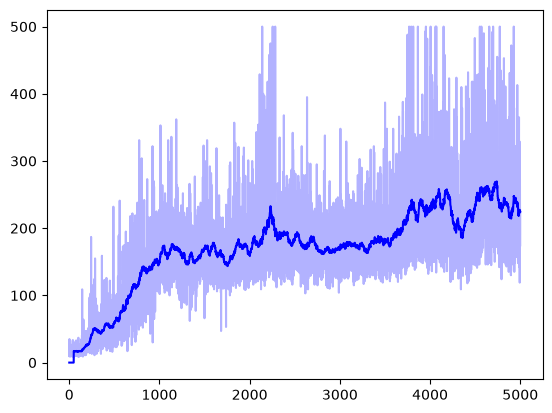

In [16]:
# Results and Plotting

env = gym.make("CartPole-v1", render_mode="rgb_array")

policy = PolicyApprox(
    n_states=len(env.observation_space.low), n_actions=env.action_space.n
)
V = VApprox(n_states=len(env.observation_space.low))

actor_critic_rewards = actor_critic(env, policy, V, num_episodes=5000)

plt.figure()
plt.clf()
plt.plot(smooth_data(actor_critic_rewards, window_width=50), "b")
plt.plot(actor_critic_rewards, "b", alpha=0.3)
plt.show()

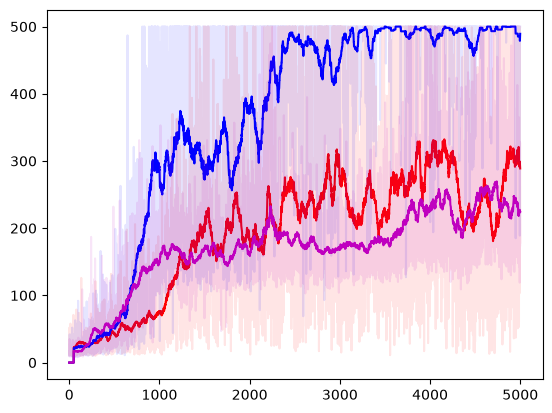

In [17]:
# Show all three on the same plot
plt.figure()
plt.clf()
rewards_list = [
    REINFORCE_rewards,
    REINFORCE_with_baseline_rewards,
    actor_critic_rewards,
]
for rewards, fmt in zip(rewards_list, ["r", "b", "m"]):
    plt.plot(rewards, fmt, alpha=0.1)
    plt.plot(smooth_data(rewards, window_width=50), fmt)
plt.show()

## P5.3 Continuous Action Policy Optimization

Next you will tackle a continuous action space, something for which policy gradient methods are well-suited. You have already implemented the training algorithms in P5.2! All that is left is to define the approximate policy function.

You will tackle the Pendulum environment, detailed here: https://gymnasium.farama.org/environments/classic_control/pendulum/

**TASK** Complete the `PolicyApproxGaussian` class. I have provided you with some starter code here. Note that the `forward` function returns a two-element tuple, that consists of the mean and standard deviation that will serve as inputs to the Normal/Gaussian distribution. The mean is scaled by `2 * tanh` to match the Pendulum's torque range of $[-2, 2]$, and `softplus` keeps the standard deviation positive. Fortunately, PyTorch has a number of built-in functions for this purpose, and defines everything you need to sample from a Gaussian distribution. Use the `torch.distributions` module [ documentation : https://pytorch.org/docs/stable/distributions.html ] to define the `sample_action` and `get_action_log_prob` functions in the partial implementation below. Note that this implementation is not epsilon-greedy, so don't worry about picking a "uniform random" action some percent of the time.

**CODE** Include your implementations of `sample_action` and `get_action_log_prob` in your writeup.

> **Note: each of the three training cells below takes about 3–5 minutes, and you will run them twice (for `g=2.0` and `g=5.0`).**

**PLOTS** Run the code below and include the resulting plots—showing the results for each approach on the Pendulum problem—in your writeup. If your policy code is set up properly, it should run without error. [In my experiments, the policy did fairly well much of the time, though not quite always; if you are confident in your implementation, running it again may yield better results. You can tune the parameters if you like, though I do not believe it will be necessary, and will take time (and sanity) you need not lose to 
this assignment.]

**TASK+PLOTS** Change the pendulum environment gravity parameter `g` to `5.0` (m/s^2) in the setup cell and rerun the results. Include the resulting three-curve plot in your writeup.

**QUESTION** (5–7 sentences) How does the performance change when you increase the gravity. Why? What does ideal behavior look like? Why is it so difficult to learn this behavior? Comment on what might be necessary to achieve better performance. *Note: you may need to look deeper into the pendulum environment or reason how you might solve this problem; you might also want to visualize your policy using the visualization code I have provided below.*

In [18]:
## Starter Code


class PolicyApproxGaussian(torch.nn.Module):
    def __init__(self, n_states):
        super().__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(n_states, 16),
            nn.Tanh(),
            nn.Linear(16, 16),
            nn.Tanh(),
            nn.Linear(16, 2),
        )

    def sample_action(self, state, epsilon=0.0):
        action_means, action_stddevs = self(state)
        action_stddevs = action_stddevs + 1e-6  # A trick to improve numerical stability
        if epsilon > 0.0:
            raise ValueError("No 'epsilon greedy' for this policy.")
        dist = torch.distributions.Normal(action_means, action_stddevs)
        action = dist.sample()  # sample() does not track gradients
        
        
        # You may need to use action.numpy() if needed to move the action out of PyTorch
        return action.numpy()

    def get_action_log_prob(self, state, action):
        action_means, action_stddevs = self(state)
        action_stddevs = action_stddevs + 1e-6  # A trick to improve numerical stability
        # Note: It's important that you *don't* use .numpy() or .detach() here!
        # That gradient is how training works!
        dist = torch.distributions.Normal(action_means, action_stddevs)
        action = torch.as_tensor(action, dtype=torch.float)
        return dist.log_prob(action).sum()
    
    def forward(self, state):
        output = self.linear_relu_stack(torch.tensor(state, dtype=torch.float))
        return 2 * torch.tanh(output[0]), nn.functional.softplus(output[1])

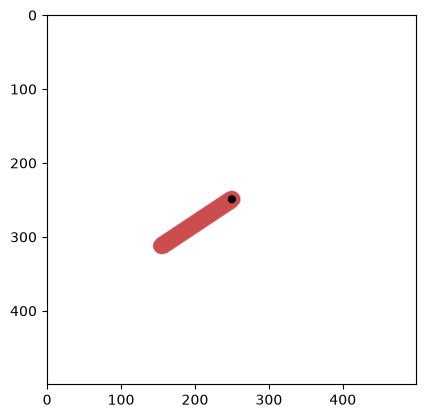

In [19]:
# Visualization Code (random policy)

env_cont = gym.make("Pendulum-v1", g=2.0, render_mode="rgb_array")
policy = PolicyApproxGaussian(n_states=len(env_cont.observation_space.low))
rollout_data = rollout(env_cont, policy, epsilon=0, do_visualize=True)

In [28]:
# Results and Plotting: setup (change g here for the g=5.0 question)

# I have provided you with a slightly different V function.
# I found it to work better for the Pendulum example.


class VApproxDeeper(torch.nn.Module):
    def __init__(self, n_states):
        super().__init__()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(n_states, 16),
            nn.Tanh(),
            nn.Linear(16, 16),
            nn.Tanh(),
            nn.Linear(16, 1),
        )

    def forward(self, state):
        return 100 * self.linear_relu_stack(torch.tensor(state, dtype=torch.float))


env_cont = gym.make("Pendulum-v1", g=5.0, render_mode="rgb_array")

In [29]:
# Results and Plotting: REINFORCE (takes about 3-5 minutes)
policy = PolicyApproxGaussian(n_states=len(env_cont.observation_space.low))
REINFORCE_rewards = reinforce(
    env_cont, policy, num_episodes=5000, learning_rate=0.001, gamma=0.98, epsilon0=0.0
)

0 -942.5390113907056 tensor(-39228.8438, grad_fn=<SubBackward0>)
100 -1301.313574217291 tensor(-51524.6172, grad_fn=<SubBackward0>)
200 -1157.5017292193763 tensor(-48031.6562, grad_fn=<SubBackward0>)
300 -1587.0059466732632 tensor(-60455.2891, grad_fn=<SubBackward0>)
400 -1676.9555625948346 tensor(-64104.9492, grad_fn=<SubBackward0>)
500 -978.1440713999461 tensor(-40706.2148, grad_fn=<SubBackward0>)
600 -1039.7587699579165 tensor(-39212.4180, grad_fn=<SubBackward0>)
700 -1481.1490477219556 tensor(-56511.7422, grad_fn=<SubBackward0>)
800 -1059.9146329833445 tensor(-40948.8945, grad_fn=<SubBackward0>)
900 -1048.0742943151017 tensor(-40806.4414, grad_fn=<SubBackward0>)
1000 -1268.3789879059925 tensor(-47174.0273, grad_fn=<SubBackward0>)
1100 -1146.8689568718637 tensor(-45373.1602, grad_fn=<SubBackward0>)
1200 -1281.1432297850376 tensor(-48294.5117, grad_fn=<SubBackward0>)
1300 -1562.0865911014037 tensor(-59909.1133, grad_fn=<SubBackward0>)
1400 -1337.320602406895 tensor(-58810.5508, grad_

In [30]:
# Results and Plotting: REINFORCE with Baseline (takes about 3-5 minutes)
policy = PolicyApproxGaussian(n_states=len(env_cont.observation_space.low))
V = VApproxDeeper(n_states=len(env_cont.observation_space.low))
REINFORCE_baseline_rewards = reinforce_with_baseline(
    env_cont,
    policy,
    V,
    num_episodes=5000,
    learning_rate=0.001,
    gamma=0.98,
    epsilon0=0.0,
)

0 -1452.3308264531183 -51450.7734375
100 -1498.8549670156974 -22222.060546875
200 -1486.2737272007744 -13577.818359375
300 -1314.5160777393858 -4072.77197265625
400 -1413.0439934892033 -7141.42724609375
500 -895.7403040170182 8203.6328125
600 -879.1016383707533 7363.162109375
700 -815.5297403871402 2542.29541015625
800 -1179.800876341487 -3662.83984375
900 -1189.4915938283395 0.15317916870117188
1000 -996.8445012184941 -25153.677734375
1100 -836.9057864586772 -1343.6976318359375
1200 -883.2721431541872 2924.862060546875
1300 -872.1586543241108 -264.2051696777344
1400 -764.706181714663 2692.1328125
1500 -694.1999725600052 -2728.250732421875
1600 -1235.3793867314707 -6092.005859375
1700 -1178.0287736682583 -630.8870239257812
1800 -1056.4336590443481 3088.308349609375
1900 -713.1339910323187 -5183.71484375
2000 -622.3782123802489 4185.1201171875
2100 -884.4262185376347 5113.169921875
2200 -795.3031116164985 -510.1815185546875
2300 -589.3754823559109 5722.24951171875
2400 -575.015448978416

In [31]:
# Results and Plotting: Actor-Critic (takes about 3-5 minutes)
policy = PolicyApproxGaussian(n_states=len(env_cont.observation_space.low))
V = VApproxDeeper(n_states=len(env_cont.observation_space.low))
actor_critic_rewards = actor_critic(
    env_cont,
    policy,
    V,
    num_episodes=5000,
    learning_rate=0.001,
    gamma=0.98,
    epsilon0=0.0,
)

0 -1497.8495705980504 -1621.3785400390625
100 -1640.1361411989985 -1304.4150390625
200 -1566.6000512858798 -249.32972717285156
300 -1764.2485673475821 -379.0802001953125
400 -1802.152870742622 -193.85142517089844
500 -1683.8453136641435 -80.23760986328125
600 -1780.8240718968057 39.74969482421875
700 -1797.0519788464446 26.043716430664062
800 -1745.167284807393 -126.76889038085938
900 -1767.1247766102156 -108.492431640625
1000 -1696.4772582380397 27.272628784179688
1100 -1800.4266613806444 -281.92938232421875
1200 -1704.843692814383 36.962646484375
1300 -1761.4745848682326 26.591064453125
1400 -1818.166754323888 330.683837890625
1500 -1709.7027510596051 -151.47610473632812
1600 -1662.3596713141233 518.7861328125
1700 -1520.0953542970472 80.8065185546875
1800 -1751.6937406278369 -260.8639831542969
1900 -1669.6310568766114 -82.48040771484375
2000 -1637.8151060601706 -56.10595703125
2100 -1405.6302497626218 144.5665283203125
2200 -1418.3504554653405 491.4271240234375
2300 -1762.8205902799

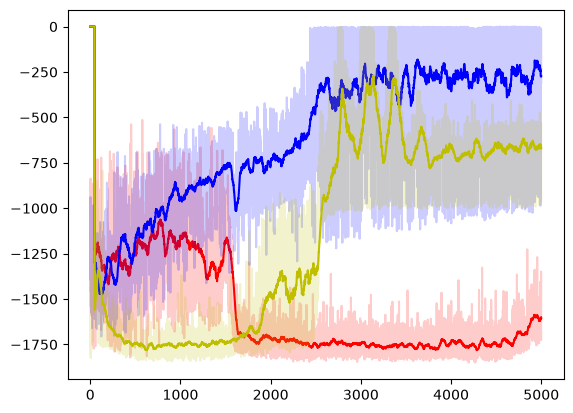

In [33]:
# Show all three on the same plot
plt.figure()
plt.clf()
rewards_list = [REINFORCE_rewards, REINFORCE_baseline_rewards, actor_critic_rewards]
for rewards, fmt in zip(rewards_list, ["r", "b", "y"]):
    plt.plot(rewards, fmt, alpha=0.2)
    plt.plot(smooth_data(rewards, window_width=50), fmt)
plt.show()

Num steps before failure: 200


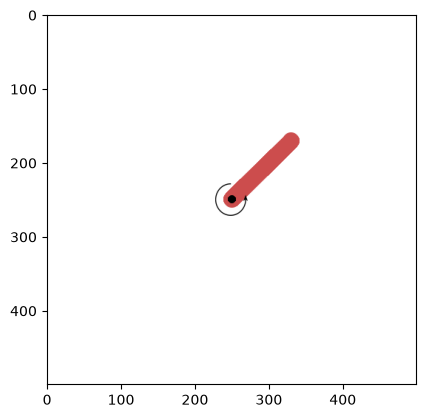

In [25]:
# Visualization
rollout_data = rollout(env_cont, policy, epsilon=0, do_visualize=True)
print(f"Num steps before failure: {len(rollout_data)}")

## P5.4 Running PPO

While I do not want you to *implement* PPO, I did want you to play around with it a bit. I have found a package that implements PPO and some utilities for fast training, data logging, etc. You'll use this instead for this final question.

**TASK** Run the training and evaluation code that follows for `gravity = 2.0` and `gravity = 5.0` and `gravity = 9.81`. Run the code a few times to see how performance varies with random seed.

**PLOTS** When run, the code will generate "monitor.csv" files in the local folder `PPO_monitor_outs` that the code below reads in and plots. Include plots for each value of gravity.

**QUESTION** (3–4 sentences) How quickly does the system learn as a function of the gravity parameter. Comment on how this is or is not consistent with your results from your own implementation?

Using cpu device


----------------------------------
| rollout/           |           |
|    ep_len_mean     | 200       |
|    ep_rew_mean     | -1.16e+03 |
| time/              |           |
|    fps             | 5247      |
|    iterations      | 1         |
|    time_elapsed    | 1         |
|    total_timesteps | 8192      |
----------------------------------
------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 200          |
|    ep_rew_mean          | -1.14e+03    |
| time/                   |              |
|    fps                  | 2914         |
|    iterations           | 2            |
|    time_elapsed         | 5            |
|    total_timesteps      | 16384        |
| train/                  |              |
|    approx_kl            | 0.0021018959 |
|    clip_fraction        | 0.0113       |
|    clip_range           | 0.2          |
|    entropy_loss         | -1.42        |
|    explained_variance   | 0.00193      |
|    

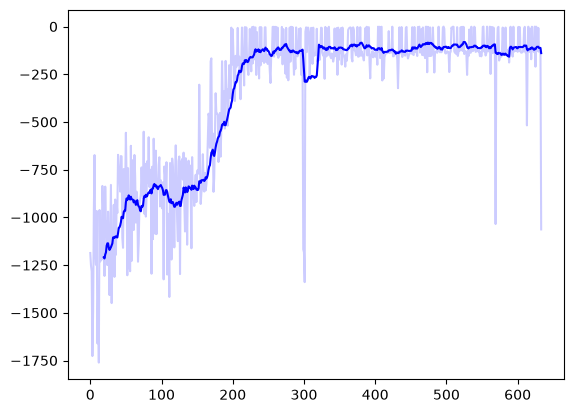

In [38]:
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.env_util import make_vec_env
import pandas as pd

gravity = 5
env_cont = gym.make("Pendulum-v1", g=gravity, render_mode="rgb_array")

# Parallel environments
vec_env = make_vec_env(
    "Pendulum-v1", n_envs=4, env_kwargs={"g": gravity}, monitor_dir="PPO_monitor_outs"
)
model = PPO("MlpPolicy", vec_env, verbose=1).learn(500000)

results_df = pd.read_csv("PPO_monitor_outs/0.monitor.csv", header=1)
plt.figure()
plt.plot(results_df["r"], "b", alpha=0.2)
plt.plot(results_df.rolling(20).mean()["r"], "b")
plt.show()